# Agente de trading con Q-Learning

Esta libreta resuelve la parte de **Q-Learning** de la práctica (la parte de SARSA la realiza otro miembro del grupo). Se reutilizan sin modificaciones el entorno `SimpleTradingEnv` y las cuatro funciones generadoras de precios de `taller_trader.ipynb`.

**Contenido**

1. Configuración, entorno y generadores de precios
2. Análisis exploratorio del estado: ¿qué información aporta la tendencia?
3. Discretización del estado
4. Agente Q-Learning
5. Protocolo de evaluación y *baselines*
6. Ajuste de hiperparámetros ($\alpha$, $\gamma$, nº de intervalos, $\epsilon$ y nº de episodios)
7. Entrenamiento final, curvas de aprendizaje y convergencia
8. Evaluación en test y tabla comparativa
9. Análisis de las políticas aprendidas
10. Más allá de los mínimos: estado ampliado y *Double* Q-Learning
11. Exportación de resultados (para combinar con SARSA) y conclusiones

**Protocolo común.** Para que los resultados de SARSA sean comparables, los dos agentes deberían evaluarse sobre las **mismas series de test**: semillas `SEED_TEST + i` para `i = 0..99`, con `N_STEPS = 500`. Ver la sección 5.

## 1. Configuración, entorno y generadores

In [1]:
import os
import time
import itertools

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import gymnasium as gym
from gymnasium import spaces
from joblib import Parallel, delayed, dump, load

N_STEPS = 500          # longitud de cada serie de precios (igual que en el enunciado)
N_VAL = 30             # series de validación (selección de hiperparámetros)
N_TEST = 100           # series de test (evaluación final; nunca se usan para ajustar)
N_SEEDS = 5            # semillas de entrenamiento independientes para el modelo final

# Rangos de semillas disjuntos: entrenamiento, calibración de la discretización, validación y test
SEED_TRAIN, SEED_CALIB, SEED_VAL, SEED_TEST = 0, 100_000, 500_000, 900_000

N_JOBS = -1
FIG_DIR = "figuras_qlearning"      # figuras para el informe
CACHE_DIR = "cache_qlearning"      # resultados de las búsquedas y agentes entrenados
os.makedirs(FIG_DIR, exist_ok=True)
os.makedirs(CACHE_DIR, exist_ok=True)

# Si es False y existe la caché, se cargan los resultados en lugar de reentrenar
# (la ejecución completa desde cero tarda ~1 h con 12 núcleos).
RECOMPUTE = False


def cached(path, compute):
    """Carga el objeto de la caché o lo calcula y lo guarda."""
    if RECOMPUTE or not os.path.exists(path):
        t0 = time.perf_counter()
        dump(compute(), path)
        print(f"{os.path.basename(path)}: calculado en {time.perf_counter() - t0:.0f} s")
    return load(path)

# Colores fijos por entidad (se mantienen en todas las figuras)
COLORS = {"Q-Learning": "#2a78d6", "Buy & Hold": "#eb6834", "Aleatorio": "#1baf7a",
          "Momentum (regla)": "#eda100", "Contrarian (regla)": "#e87ba4", "Siempre fuera": "#8a8984",
          "Q-Learning (estado ampliado)": "#6250d6", "Double Q-Learning": "#008300"}

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3, "axes.titleweight": "bold"})

El entorno es **exactamente el del enunciado** (misma dinámica, comisiones y recompensa).

In [2]:
class SimpleTradingEnv(gym.Env):
    metadata = {"render_modes": ["human"]}

    def __init__(self, prices):
        super(SimpleTradingEnv, self).__init__()
        self.prices = prices
        self.max_steps = len(prices) - 1

        # Acciones: 0 = Vender, 1 = Mantener, 2 = Comprar
        self.action_space = spaces.Discrete(3)

        # Estado: [tendencia_precio (-1 a 1), posicion_actual (0 o 1)]
        self.observation_space = spaces.Box(
            low=np.array([-1.0, 0], dtype=np.float32),
            high=np.array([1.0, 1], dtype=np.float32),
            dtype=np.float32
        )

    def reset(self, seed=None):
        super().reset(seed=seed)
        self.current_step = 5  # Empezar con suficiente historia para la media
        self.position = 0      # 0: sin activo, 1: con activo

        # Gestión del capital
        self.initial_balance = 1000.0
        self.balance = self.initial_balance  # Valor total del portafolio (Efectivo + Activos)
        self.cash = self.initial_balance     # Dinero en efectivo disponible
        self.shares = 0.0                    # Cantidad de acciones poseídas

        return self._get_obs(), {}

    def _get_obs(self):
        # Calcular tendencia simple basada en los últimos 5 pasos
        window = self.prices[self.current_step - 5 : self.current_step + 1]
        trend = (window[-1] - np.mean(window)) / np.mean(window)
        return np.array([np.clip(trend, -1.0, 1.0), self.position], dtype=np.float32)

    def step(self, action):
        prev_price = self.prices[self.current_step]
        self.current_step += 1
        curr_price = self.prices[self.current_step]

        reward = 0.0
        cost_rate = 0.001  # Comisión del 0.1% por transacción

        # 1. Ejecutar acciones y actualizar efectivo/acciones
        if action == 2 and self.position == 0:  # Comprar
            # Usar todo el efectivo disponible para comprar acciones al precio anterior
            commission = self.cash * cost_rate
            effective_cash = self.cash - commission
            self.shares = effective_cash / prev_price
            self.cash = 0.0
            self.position = 1
            reward -= cost_rate

        elif action == 0 and self.position == 1:  # Vender
            # Vender todas las acciones al precio anterior
            sale_value = self.shares * prev_price
            commission = sale_value * cost_rate
            self.cash = sale_value - commission
            self.shares = 0.0
            self.position = 0
            reward -= cost_rate

        # 2. Calcular recompensa por variación del precio si mantiene la posición
        if self.position == 1:
            price_change = (curr_price - prev_price) / prev_price
            reward += price_change

        # 3. Actualizar el balance total (Net Worth) al finalizar el paso
        if self.position == 1:
            self.balance = self.cash + (self.shares * curr_price)
        else:
            self.balance = self.cash

        terminated = self.current_step >= self.max_steps
        truncated = False

        # Opcional: puedes pasar el balance actual en el diccionario de info
        info = {"balance": self.balance}

        return self._get_obs(), reward, terminated, truncated, info

Generadores de precios del enunciado (sin cambios):

In [3]:
def generar_precios(n_steps=1000):
    # Combinar una tendencia suave (drift) + componente cíclico + ruido
    t = np.linspace(0, 50, n_steps)
    drift = 0.0005 * t
    ciclo = np.sin(t) * 0.05
    ruido = np.random.normal(0, 0.1, n_steps)

    # Precio base acumulado
    retornos = drift + ciclo + ruido
    precios = 100 * np.cumprod(1 + retornos)
    return precios


def generar_precios_browniano(n_steps=1000, start_price=100.0, mu=0.0001, sigma=0.02):
    dt = 1.0
    retornos = np.random.normal((mu - 0.5 * sigma**2) * dt, sigma * np.sqrt(dt), n_steps)
    precios = start_price * np.cumprod(np.exp(retornos))
    return precios


def generar_precios_reversion_media(n_steps=1000, start_price=100.0, mean_price=100.0, kappa=0.05, volatility=0.02):
    precios = np.zeros(n_steps)
    precios[0] = start_price
    for t in range(1, n_steps):
        delta = kappa * (mean_price - precios[t-1]) + np.random.normal(0, volatility * mean_price)
        precios[t] = precios[t-1] + delta
        precios[t] = max(precios[t], 0.1)
    return precios


def generar_precios_regimenes(n_steps=1000, start_price=100.0):
    precios = np.zeros(n_steps)
    precios[0] = start_price
    estado = 0
    retornos = []
    for _ in range(n_steps):
        if np.random.rand() < 0.02:
            estado = 1 - estado
        if estado == 0:
            ret = np.random.normal(0.001, 0.01)
        else:
            ret = np.random.normal(-0.0015, 0.025)
        retornos.append(ret)
    retornos = np.array(retornos)
    precios = start_price * np.cumprod(1 + retornos)
    precios = np.maximum(precios, 0.1)
    return precios


GENERATORS = {
    "Tendencia + ciclo": generar_precios,
    "Browniano": generar_precios_browniano,
    "Reversión a la media": generar_precios_reversion_media,
    "Regímenes": generar_precios_regimenes,
}


def make_series(gen_name, seed, n=N_STEPS):
    """Serie reproducible: los generadores usan el RNG global de numpy, así que fijamos la semilla."""
    np.random.seed(seed)
    return GENERATORS[gen_name](n)

## 2. Análisis exploratorio del estado

Antes de entrenar conviene saber **qué puede aprender el agente**. Su única información de mercado es la tendencia de las 6 últimas observaciones. Si la tendencia no predice el retorno del paso siguiente, ningún algoritmo tabular podrá superar sistemáticamente a una estrategia pasiva. Para cada generador medimos:

- la distribución de la tendencia, que sirve para diseñar la discretización;
- la correlación entre la tendencia y el retorno del paso siguiente, que es la señal explotable;
- el retorno medio por paso, que indica si *buy & hold* tiene esperanza positiva.

In [4]:
def trend_series(p):
    """Tendencia que observa el agente en cada paso (misma fórmula que _get_obs)."""
    out = np.empty(len(p) - 6)
    for i, k in enumerate(range(5, len(p) - 1)):
        w = p[k - 5:k + 1]
        out[i] = np.clip((w[-1] - w.mean()) / w.mean(), -1, 1)
    return out


eda_rows, eda_trends = [], {}
for name in GENERATORS:
    trs, nxt = [], []
    for i in range(100):
        p = make_series(name, SEED_CALIB + i)
        trs.append(trend_series(p))
        nxt.append(p[6:] / p[5:-1] - 1)          # retorno del paso k -> k+1 (el que cobra la recompensa)
    trs, nxt = np.concatenate(trs), np.concatenate(nxt)
    eda_trends[name] = trs
    q = np.quantile(trs, [0.05, 0.5, 0.95])
    eda_rows.append({"Generador": name, "Tendencia p5": q[0], "Tendencia mediana": q[1], "Tendencia p95": q[2],
                     "Corr(tendencia, ret. siguiente)": np.corrcoef(trs, nxt)[0, 1],
                     "Retorno medio por paso (%)": 100 * nxt.mean(), "Volatilidad por paso (%)": 100 * nxt.std()})
eda = pd.DataFrame(eda_rows).set_index("Generador")
eda.round(4)

,Tendencia p5,Tendencia mediana,Tendencia p95,"Corr(tendencia, ret. siguiente)",Retorno medio por paso (%),Volatilidad por paso (%)
Generador,,,,,,
Tendencia + ciclo,-0.2256,0.0192,0.2763,0.1933,1.2177,10.6352
Browniano,-0.0411,-0.0004,0.0406,0.0034,0.0031,2.0028
Reversión a la media,-0.0401,0.0000,0.0401,-0.0425,0.0214,2.0452
Regímenes,-0.0428,0.0004,0.0351,0.0015,-0.0220,1.8750


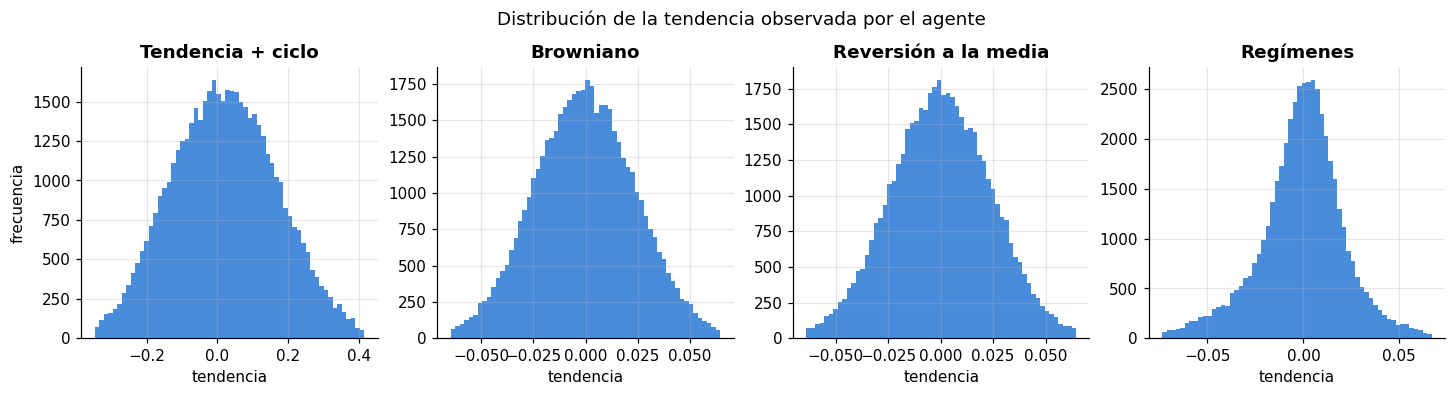

In [5]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.2))
for ax, name in zip(axes, GENERATORS):
    trs = eda_trends[name]
    lo, hi = np.quantile(trs, [0.005, 0.995])
    ax.hist(trs[(trs > lo) & (trs < hi)], bins=60, color=COLORS["Q-Learning"], alpha=0.85)
    ax.set_title(name)
    ax.set_xlabel("tendencia")
axes[0].set_ylabel("frecuencia")
fig.suptitle("Distribución de la tendencia observada por el agente", y=1.04)
plt.savefig(f"{FIG_DIR}/eda_tendencia.png", bbox_inches="tight")
plt.show()

**Lectura del análisis exploratorio**

- **Escala.** La tendencia vive en rangos muy distintos según el generador: en torno a ±0.3 en *tendencia + ciclo* (ruido del 10 % por paso) y en torno a ±0.03 en los demás. Unos intervalos uniformes sobre [-1, 1] dejarían casi todos los datos en uno o dos intervalos. Por eso discretizamos con **cuantiles empíricos calculados para cada generador**.
- **Señal explotable.** Solo *tendencia + ciclo* tiene una correlación claramente positiva entre tendencia y retorno siguiente: el componente cíclico de los retornos es persistente, así que ahí cabe esperar una estrategia de **momentum**. En *reversión a la media* la correlación es ligeramente negativa, lo que sugiere una señal *contrarian* débil. En *browniano* y *regímenes* es prácticamente nula.
- **Implicación.** En los generadores sin señal, lo racional es una estrategia pasiva: siempre dentro si la deriva compensa, o siempre fuera si no. Se comprobará si Q-Learning llega a esa conclusión.

## 3. Discretización del estado

Q-Learning tabular necesita estados discretos. El estado discreto es `(intervalo de tendencia, posición)`, con un total de `n_bins × 2` estados.

- **Límites de los intervalos.** Son los cuantiles de la tendencia en 40 series de **calibración**, con semillas disjuntas de las de entrenamiento, validación y test. Así cada intervalo recibe aproximadamente la misma cantidad de visitas, y el aprendizaje es igual de rápido en todos los estados.
- **Número de intervalos.** Se trata como hiperparámetro (sección 6). Con pocos intervalos el estado pierde resolución; con muchos, hay menos visitas por estado y las estimaciones de Q son más ruidosas.
- **Observaciones adicionales.** La clase admite observaciones con más variables (por ejemplo, volatilidad), que se usan en la sección 10.

In [6]:
class Discretizer:
    """Convierte una observación continua en un índice de estado discreto.

    bins: {índice de la observación: nº de intervalos}. La posición (obs[1]) se añade siempre como
    última dimensión binaria.
    """

    def __init__(self, gen_name, bins={0: 10}, env_cls=SimpleTradingEnv, n_series=40):
        obs = []
        for i in range(n_series):
            env = env_cls(make_series(gen_name, SEED_CALIB + i))
            o, _ = env.reset()
            done = False
            while not done:
                obs.append(o)
                o, _, done, _, _ = env.step(1)
        obs = np.array(obs)
        self.idx = list(bins)
        self.edges = [np.quantile(obs[:, j], np.linspace(0, 1, bins[j] + 1)[1:-1]) for j in self.idx]
        self.sizes = [bins[j] for j in self.idx] + [2]
        self.n_states = int(np.prod(self.sizes))

    def __call__(self, obs):
        s = 0
        for e, j, size in zip(self.edges, self.idx, self.sizes):
            s = s * size + int(np.searchsorted(e, obs[j]))
        return s * 2 + int(obs[1])

## 4. Agente Q-Learning

Q-Learning (*off-policy* TD control):

$$Q(s,a) \leftarrow Q(s,a) + \alpha\,\big[r + \gamma \max_{a'} Q(s',a') - Q(s,a)\big]$$

Decisiones de implementación:

- **Exploración $\epsilon$-greedy con decaimiento exponencial por episodio.** $\epsilon$ va de $\epsilon_0 = 1$ a $\epsilon_{min}$ a lo largo de una fracción `decay_frac` del entrenamiento, y después se mantiene en $\epsilon_{min}$.
- **Desempates.** En entrenamiento se desempata al azar, para no sesgar la exploración hacia la acción 0 cuando Q vale cero. En evaluación (política *greedy*) se desempata a favor de *mantener*, la única acción neutra en todos los estados.
- **Estados terminales.** En el último paso no hay bootstrap.
- **Una serie de precios nueva por episodio,** generada por la misma función, como pide el enunciado.
- **Double Q-Learning.** Con `double=True` se usan dos tablas, para reducir el sesgo de sobreestimación del operador $\max$ (sección 10).

In [7]:
class QLearningAgent:
    def __init__(self, n_states, alpha=0.1, gamma=0.9, eps_start=1.0, eps_min=0.01,
                 decay_frac=0.7, double=False, seed=0):
        self.alpha, self.gamma = alpha, gamma
        self.eps_start, self.eps_min, self.decay_frac = eps_start, eps_min, decay_frac
        self.double = double
        self.rng = np.random.default_rng(seed)
        self.Q = np.zeros((n_states, 3))
        self.Q2 = np.zeros((n_states, 3)) if double else None

    def q_values(self, s):
        return self.Q[s] + self.Q2[s] if self.double else self.Q[s]

    def act(self, s, eps):
        if self.rng.random() < eps:
            return int(self.rng.integers(3))
        q = self.q_values(s)
        best = np.flatnonzero(q == q.max())
        return int(best[0] if len(best) == 1 else self.rng.choice(best))

    def greedy(self, s):
        q = self.q_values(s)
        best = np.flatnonzero(q == q.max())
        return 1 if 1 in best else int(best[0])

    def update(self, s, a, r, s2, done):
        if not self.double:
            target = r if done else r + self.gamma * self.Q[s2].max()
            self.Q[s, a] += self.alpha * (target - self.Q[s, a])
        else:
            A, B = (self.Q, self.Q2) if self.rng.random() < 0.5 else (self.Q2, self.Q)
            target = r if done else r + self.gamma * B[s2, int(A[s2].argmax())]
            A[s, a] += self.alpha * (target - A[s, a])

    def greedy_policy(self, disc):
        return lambda obs: self.greedy(disc(obs))


def train_q_learning(gen_name, disc, n_episodes=2000, env_cls=SimpleTradingEnv, seed=0,
                     val_series=None, eval_every=100, **hp):
    """Entrena un agente con una serie nueva por episodio y, opcionalmente, mide en validación."""
    agent = QLearningAgent(disc.n_states, seed=seed, **hp)
    decay = (agent.eps_min / agent.eps_start) ** (1.0 / max(1, agent.decay_frac * n_episodes))
    eps = agent.eps_start
    hist = {"ep_reward": np.zeros(n_episodes), "val_ep": [], "val_logret": [], "eps": np.zeros(n_episodes)}
    t0 = time.perf_counter()
    for ep in range(n_episodes):
        env = env_cls(make_series(gen_name, SEED_TRAIN + seed * 1_000_000 + ep))
        obs, _ = env.reset()
        s = disc(obs)
        done, total = False, 0.0
        while not done:
            a = agent.act(s, eps)
            obs, r, done, _, _ = env.step(a)
            s2 = disc(obs)
            agent.update(s, a, r, s2, done)
            s, total = s2, total + r
        hist["ep_reward"][ep], hist["eps"][ep] = total, eps
        eps = max(agent.eps_min, eps * decay)
        if val_series is not None and ((ep + 1) % eval_every == 0 or ep == 0):
            res = evaluate(val_series, lambda i: agent.greedy_policy(disc), env_cls)
            hist["val_ep"].append(ep + 1)
            hist["val_logret"].append(res["log_ret"].mean())
    hist["train_time"] = time.perf_counter() - t0   # incluye las evaluaciones de validación
    return agent, hist

## 5. Protocolo de evaluación y *baselines*

- Cada política se ejecuta, sin explorar, sobre las **mismas 100 series de test**. Ninguna de ellas se ha usado para entrenar ni para elegir hiperparámetros.
- **Métricas por serie:**
  - **retorno final** del capital (1000 € iniciales);
  - **log-retorno** $\log(B_T/B_0)$;
  - **Sharpe** de los retornos por paso del capital, anualizado con $\sqrt{252}$ suponiendo pasos diarios (vale 0 si la estrategia nunca invierte);
  - **máximo *drawdown***;
  - **número de operaciones**;
  - **fracción del tiempo invertido**.
- **Agregación.** Se resume con la **media del log-retorno** (equivale al retorno geométrico medio) y con la **mediana** del retorno, en lugar de la media aritmética. En *tendencia + ciclo* los capitales finales llegan a multiplicarse por cientos y unas pocas series dominarían la media.
- **Baselines:**
  - aleatorio (el del enunciado);
  - *buy & hold*: compra en el primer paso y no vende;
  - siempre fuera: nunca invierte, retorno 0;
  - dos reglas fijas, *momentum* (dentro si tendencia > 0) y *contrarian* (dentro si tendencia < 0). Sirven para interpretar qué ha aprendido el agente.

In [8]:
def run_episode(prices, policy, env_cls=SimpleTradingEnv):
    env = env_cls(prices)
    obs, _ = env.reset()
    balances, positions, trades, done = [env.balance], [], 0, False
    while not done:
        a = policy(obs)
        positions.append(env.position)
        prev = env.position
        obs, _, done, _, info = env.step(a)
        trades += int(prev != env.position)
        balances.append(info["balance"])
    return np.array(balances), np.array(positions), trades


def episode_metrics(balances, positions, trades):
    rets = balances[1:] / balances[:-1] - 1
    peak = np.maximum.accumulate(balances)
    sd = rets.std()
    return {"final": balances[-1], "ret": balances[-1] / balances[0] - 1,
            "log_ret": np.log(balances[-1] / balances[0]),
            "sharpe": 0.0 if sd < 1e-12 else rets.mean() / sd * np.sqrt(252),
            "max_dd": ((peak - balances) / peak).max(), "trades": trades, "invested": positions.mean()}


def evaluate(series_list, make_policy, env_cls=SimpleTradingEnv):
    """make_policy(i) -> política (obs -> acción) para la serie i."""
    rows = [episode_metrics(*run_episode(p, make_policy(i), env_cls)) for i, p in enumerate(series_list)]
    return pd.DataFrame(rows)


def random_policy_factory(base_seed):
    def make(i):
        rng = np.random.default_rng(base_seed + i)
        return lambda obs: int(rng.integers(3))
    return make


BASELINES = {
    "Aleatorio": random_policy_factory(SEED_TEST),
    "Buy & Hold": lambda i: (lambda obs: 2),
    "Siempre fuera": lambda i: (lambda obs: 1),
    "Momentum (regla)": lambda i: (lambda obs: 2 if obs[0] > 0 else 0),
    "Contrarian (regla)": lambda i: (lambda obs: 2 if obs[0] < 0 else 0),
}

val_sets = {g: [make_series(g, SEED_VAL + i) for i in range(N_VAL)] for g in GENERATORS}
test_sets = {g: [make_series(g, SEED_TEST + i) for i in range(N_TEST)] for g in GENERATORS}

## 6. Ajuste de hiperparámetros

La selección se hace **solo con las series de validación**. El criterio es el **log-retorno medio en validación** de la política *greedy*, que equivale a maximizar el crecimiento geométrico del capital. Se procede en tres etapas:

1. **Rejilla principal** sobre $\alpha \in \{0.01, 0.05, 0.2\}$, $\gamma \in \{0, 0.5, 0.9, 0.99\}$ y el nº de intervalos $\in \{5, 10, 20\}$. Se entrena con 1000 episodios y 2 semillas por configuración (288 entrenamientos en paralelo).
2. **Exploración $\epsilon$:** se barren $\epsilon_{min}$ y la fracción de decaimiento con los mejores $\alpha, \gamma$ y nº de intervalos.
3. **Número de episodios:** se elige con las curvas de aprendizaje de la sección 7.

Los resultados se guardan en CSV. Al reejecutar la libreta se cargan sin recalcular, salvo que se ponga `RECOMPUTE = True`.

In [9]:
GRID_EPISODES = 1000


def grid_job(gen_name, n_bins, seed, hp, n_episodes=GRID_EPISODES):
    disc = Discretizer(gen_name, {0: n_bins})
    agent, hist = train_q_learning(gen_name, disc, n_episodes=n_episodes, seed=seed, **hp)
    res = evaluate(val_sets[gen_name], lambda i: agent.greedy_policy(disc))
    return {"gen": gen_name, "n_bins": n_bins, "seed": seed, **hp,
            "val_logret": res["log_ret"].mean(), "val_invested": res["invested"].mean(),
            "val_trades": res["trades"].mean(), "time": hist["train_time"]}


grid_path = f"{CACHE_DIR}/grid_alpha_gamma_bins.csv"
if RECOMPUTE or not os.path.exists(grid_path):
    jobs = [(g, nb, sd, {"alpha": a, "gamma": gm})
            for g in GENERATORS for a in [0.01, 0.05, 0.2] for gm in [0.0, 0.5, 0.9, 0.99]
            for nb in [5, 10, 20] for sd in range(2)]
    t0 = time.perf_counter()
    grid = pd.DataFrame(Parallel(n_jobs=N_JOBS)(delayed(grid_job)(*j) for j in jobs))
    print(f"{len(jobs)} entrenamientos en {time.perf_counter() - t0:.0f} s")
    grid.to_csv(grid_path, index=False)
grid = pd.read_csv(grid_path)
grid_mean = grid.groupby(["gen", "alpha", "gamma", "n_bins"], as_index=False)[["val_logret", "val_invested", "val_trades"]].mean()

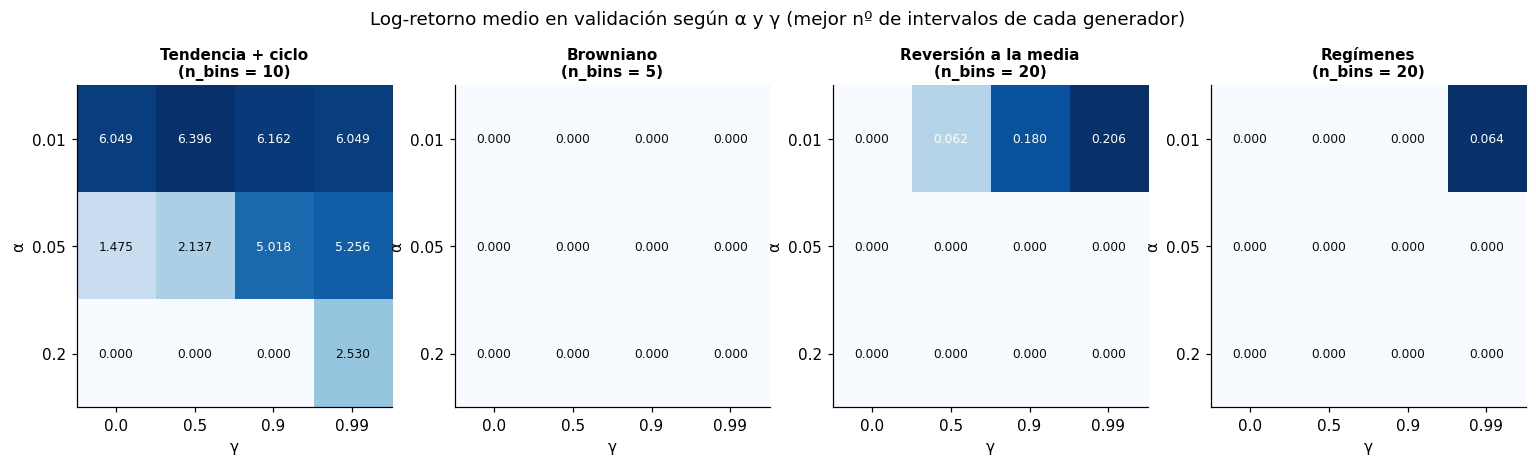

,alpha,gamma,n_bins,val_logret,val_invested,val_trades
gen,,,,,,
Tendencia + ciclo,0.01,0.50,10,6.395531,0.526046,42.850000
Browniano,0.01,0.00,5,0.000000,0.000000,0.000000
Reversión a la media,0.01,0.99,20,0.206339,0.416161,65.566667
Regímenes,0.01,0.99,20,0.064164,0.340722,24.116667


In [10]:
fig, axes = plt.subplots(1, 4, figsize=(17, 3.8))
for ax, g in zip(axes, GENERATORS):
    sub = grid_mean[grid_mean.gen == g]
    best_bins = sub.loc[sub.val_logret.idxmax(), "n_bins"]
    piv = sub[sub.n_bins == best_bins].pivot(index="alpha", columns="gamma", values="val_logret")
    im = ax.imshow(piv.values, cmap="Blues", aspect="auto")
    ax.set_xticks(range(len(piv.columns)), [str(c) for c in piv.columns])
    ax.set_yticks(range(len(piv.index)), [str(r) for r in piv.index])
    ax.set_xlabel("γ"); ax.set_ylabel("α"); ax.grid(False)
    ax.set_title(f"{g}\n(n_bins = {best_bins})", fontsize=10)
    vmid = np.nanmean(piv.values)
    for (i, j), v in np.ndenumerate(piv.values):
        ax.text(j, i, f"{v:.3f}", ha="center", va="center", fontsize=8,
                color="white" if v > vmid and np.ptp(piv.values) > 0 else "#0b0b0b")
fig.suptitle("Log-retorno medio en validación según α y γ (mejor nº de intervalos de cada generador)", y=1.06)
plt.savefig(f"{FIG_DIR}/grid_alpha_gamma.png", bbox_inches="tight")
plt.show()

best_rows = grid_mean.loc[grid_mean.groupby("gen").val_logret.idxmax()].set_index("gen").loc[list(GENERATORS)]
best_rows

**Sensibilidad al número de intervalos.** Para cada nº de intervalos se toma la mejor combinación de $\alpha$ y $\gamma$:

In [11]:
grid_mean.groupby(["gen", "n_bins"]).val_logret.max().unstack().loc[list(GENERATORS)].round(4)

n_bins,5,10,20
gen,,,
Tendencia + ciclo,6.1998,6.3955,6.3702
Browniano,0.0000,0.0000,0.0000
Reversión a la media,0.2012,0.1887,0.2063
Regímenes,0.0000,0.0000,0.0642


### Exploración: $\epsilon_{min}$ y velocidad de decaimiento

Se fijan los mejores $\alpha$, $\gamma$ y nº de intervalos de cada generador y se barren $\epsilon_{min} \in \{0.01, 0.05, 0.1\}$ y `decay_frac` $\in \{0.3, 0.6, 0.9\}$, con 3 semillas por configuración.

In [12]:
eps_path = f"{CACHE_DIR}/grid_epsilon.csv"
if RECOMPUTE or not os.path.exists(eps_path):
    jobs = []
    for g in GENERATORS:
        b = best_rows.loc[g]
        for em, df_ in itertools.product([0.01, 0.05, 0.1], [0.3, 0.6, 0.9]):
            for sd in range(3):
                jobs.append((g, int(b.n_bins), sd, {"alpha": b.alpha, "gamma": b.gamma,
                                                    "eps_min": em, "decay_frac": df_}))
    eps_grid = pd.DataFrame(Parallel(n_jobs=N_JOBS)(delayed(grid_job)(*j) for j in jobs))
    eps_grid.to_csv(eps_path, index=False)
eps_grid = pd.read_csv(eps_path)
eps_mean = eps_grid.groupby(["gen", "eps_min", "decay_frac"], as_index=False).val_logret.mean()
eps_mean.pivot_table(index="gen", columns=["eps_min", "decay_frac"], values="val_logret").loc[list(GENERATORS)].round(4)

eps_min                 0.01                    0.05                    0.10  \
decay_frac               0.3     0.6     0.9     0.3     0.6     0.9     0.3   
gen                                                                            
Tendencia + ciclo     6.1158  6.1473  6.1192  6.2740  6.2148  6.1864  6.3140   
Browniano             0.0000  0.0000  0.0000  0.0000  0.0000  0.0000  0.0000   
Reversión a la media  0.2025  0.2128  0.2023  0.1639  0.1786  0.2223  0.2128   
Regímenes             0.0665  0.0593  0.0377  0.0537  0.0681  0.0627  0.0736   

eps_min                               
decay_frac               0.6     0.9  
gen                                   
Tendencia + ciclo     6.1574  6.3140  
Browniano             0.0000  0.0000  
Reversión a la media  0.1840  0.2102  
Regímenes             0.0163  0.0794

In [13]:
best_eps = eps_mean.loc[eps_mean.groupby("gen").val_logret.idxmax()].set_index("gen")
BEST_HP = {}
for g in GENERATORS:
    b = best_rows.loc[g]
    BEST_HP[g] = {"n_bins": int(b.n_bins), "alpha": float(b.alpha), "gamma": float(b.gamma),
                  "eps_min": float(best_eps.loc[g, "eps_min"]), "decay_frac": float(best_eps.loc[g, "decay_frac"])}
pd.DataFrame(BEST_HP).T

,n_bins,alpha,gamma,eps_min,decay_frac
Tendencia + ciclo,10.0,0.01,0.50,0.10,0.3
Browniano,5.0,0.01,0.00,0.01,0.3
Reversión a la media,20.0,0.01,0.99,0.05,0.9
Regímenes,20.0,0.01,0.99,0.10,0.9


**Conclusiones del ajuste de hiperparámetros**

- **α = 0.01 es claramente la mejor opción en los cuatro mercados.**
  - Con α = 0.2, los agentes de *reversión a la media* y *regímenes* dejan de operar (log-retorno 0) y el de *tendencia + ciclo* baja de 6.40 a 5.88 en validación.
  - El motivo es que la recompensa de cada paso es casi todo ruido: volatilidades del 1–10 % por paso frente a señales de centésimas de punto. Un α pequeño promedia muchas más muestras antes de mover Q.
  - Con α grande, unas pocas pérdidas recientes hunden la estimación de «comprar» y la política acaba en «no operar», que tiene varianza cero.
- **El mejor γ depende del horizonte de la señal.**
  - En *tendencia + ciclo* basta γ = 0.5, porque la tendencia predice los retornos de los pasos inmediatos.
  - En *reversión* y *regímenes* hace falta γ = 0.99. Con un horizonte corto, la ganancia esperada del paso siguiente no compensa la comisión de entrada y el agente nunca compra. En *reversión*, el log-retorno en validación pasa de 0.003 con γ = 0 a 0.21 con γ = 0.99.
- **Nº de intervalos.** Entre 10 y 20 intervalos los resultados son parecidos, salvo en *regímenes*, que solo aprende algo con 20. Ahí la información útil está en las colas de la distribución de la tendencia (movimientos extremos), y solo una discretización fina las aísla.
- **Exploración (ε).** Su efecto es pequeño, del orden del ruido entre semillas. Se usa la mejor combinación, pero no es una decisión crítica.
- **Browniano.** En la mejor configuración de la rejilla el resultado es exactamente 0 (el agente no invierte nunca), así que los hiperparámetros «elegidos» para este mercado son un desempate arbitrario.

## 7. Entrenamiento final, curvas de aprendizaje y convergencia

Con los hiperparámetros elegidos se entrenan **5 semillas independientes por generador, con 3000 episodios cada una**, y la política *greedy* se evalúa en validación cada 100 episodios.

**Criterio de convergencia.**

1. Se suaviza la curva de validación con una media móvil de 3 puntos.
2. El nivel final es la media del último 25 % de los puntos.
3. La tolerancia es el máximo entre dos desviaciones típicas de ese tramo final, el 5 % de su valor absoluto y 0.01 de log-retorno.
4. El episodio de convergencia es el primero a partir del cual la curva ya no sale de esa banda.

El tiempo de convergencia en segundos es ese nº de episodios multiplicado por el coste medio de un episodio.

In [14]:
FINAL_EPISODES = 3000
EVAL_EVERY = 100


def convergence_episode(val_ep, val_curve, frac_final=0.25):
    v = pd.Series(val_curve).rolling(3, min_periods=1).mean().values
    tail = v[-max(2, int(len(v) * frac_final)):]
    final = tail.mean()
    tol = max(2 * tail.std(), 0.05 * abs(final), 0.01)
    inside = np.abs(v - final) <= tol
    k = len(v) - 1
    while k > 0 and inside[k - 1]:
        k -= 1
    return val_ep[k]


def final_job(gen_name, seed, hp, double=False, env_cls=SimpleTradingEnv, bins=None):
    hp = dict(hp)
    n_bins = hp.pop("n_bins")
    disc = Discretizer(gen_name, bins or {0: n_bins}, env_cls=env_cls)
    agent, hist = train_q_learning(gen_name, disc, n_episodes=FINAL_EPISODES, env_cls=env_cls, seed=seed,
                                   val_series=val_sets[gen_name], eval_every=EVAL_EVERY, double=double, **hp)
    return gen_name, seed, agent, disc, hist


final_runs = cached(f"{CACHE_DIR}/agentes_finales.joblib", lambda: Parallel(n_jobs=N_JOBS)(
    delayed(final_job)(g, sd, BEST_HP[g]) for g in GENERATORS for sd in range(N_SEEDS)))
RUNS = {g: [r for r in final_runs if r[0] == g] for g in GENERATORS}

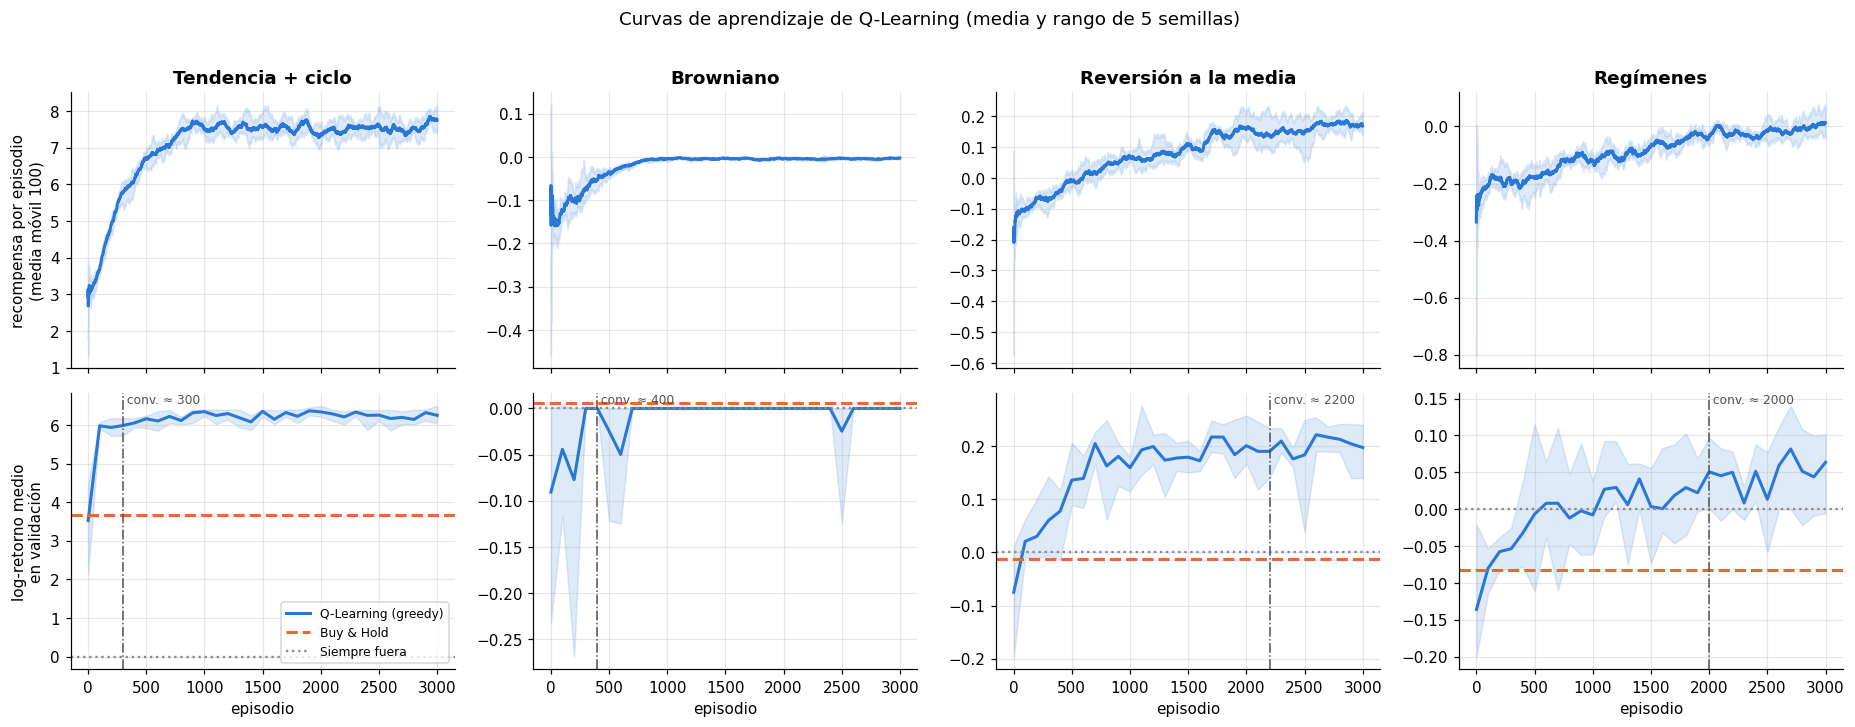

In [15]:
fig, axes = plt.subplots(2, 4, figsize=(17, 6.5), sharex=True)
for j, g in enumerate(GENERATORS):
    runs = RUNS[g]
    # Fila 1: recompensa de entrenamiento por episodio (media móvil de 100 episodios), media de semillas
    rew = np.array([pd.Series(h["ep_reward"]).rolling(100, min_periods=1).mean() for *_, h in runs])
    ax = axes[0, j]
    ax.plot(rew.mean(0), color=COLORS["Q-Learning"], lw=2)
    ax.fill_between(range(FINAL_EPISODES), rew.min(0), rew.max(0), color=COLORS["Q-Learning"], alpha=0.15)
    ax.set_title(g)
    # Fila 2: log-retorno medio de validación de la política greedy
    ax = axes[1, j]
    vals = np.array([h["val_logret"] for *_, h in runs])
    ep = runs[0][4]["val_ep"]
    ax.plot(ep, vals.mean(0), color=COLORS["Q-Learning"], lw=2, label="Q-Learning (greedy)")
    ax.fill_between(ep, vals.min(0), vals.max(0), color=COLORS["Q-Learning"], alpha=0.15)
    bh = evaluate(val_sets[g], BASELINES["Buy & Hold"])["log_ret"].mean()
    ax.axhline(bh, color=COLORS["Buy & Hold"], ls="--", lw=2, label="Buy & Hold")
    ax.axhline(0, color=COLORS["Siempre fuera"], ls=":", lw=1.5, label="Siempre fuera")
    conv = [convergence_episode(h["val_ep"], h["val_logret"]) for *_, h in runs]
    ax.axvline(np.median(conv), color="#52514e", lw=1, ls="-.")
    ax.text(np.median(conv), ax.get_ylim()[1], f" conv. ≈ {int(np.median(conv))}", va="top", fontsize=8, color="#52514e")
    ax.set_xlabel("episodio")
axes[0, 0].set_ylabel("recompensa por episodio\n(media móvil 100)")
axes[1, 0].set_ylabel("log-retorno medio\nen validación")
axes[1, 0].legend(fontsize=8, loc="lower right")
fig.suptitle("Curvas de aprendizaje de Q-Learning (media y rango de 5 semillas)", y=1.01)
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/curvas_aprendizaje.png", bbox_inches="tight")
plt.show()

En la fila superior, la recompensa de entrenamiento incluye la exploración, así que sube a medida que $\epsilon$ decae. La fila inferior mide la política *greedy* sobre validación, que es la que importa. La línea vertical marca el episodio de convergencia mediano.

## 8. Evaluación en test y tabla comparativa

In [16]:
def summarize(res, name, gen, extra=None):
    row = {"Generador": gen, "Agente": name,
           "Log-ret. medio": res["log_ret"].mean(),
           "Ret. geométrico (%)": 100 * (np.exp(res["log_ret"].mean()) - 1),
           "Ret. mediano (%)": 100 * res["ret"].median(),
           "Sharpe": res["sharpe"].mean(),
           "Max DD (%)": 100 * res["max_dd"].mean(),
           "Operaciones": res["trades"].mean(),
           "% tiempo invertido": 100 * res["invested"].mean()}
    row.update(extra or {})
    return row


test_results, rows = {}, []
for g in GENERATORS:
    for name, factory in BASELINES.items():
        res = evaluate(test_sets[g], factory)
        test_results[(g, name)] = res
        rows.append(summarize(res, name, g))
    # Q-Learning: se evalúan las 5 semillas; las métricas se promedian sobre semillas x series
    per_seed = [evaluate(test_sets[g], lambda i, a=agent, d=disc: a.greedy_policy(d)) for _, _, agent, disc, _ in RUNS[g]]
    res = pd.concat(per_seed, ignore_index=True)
    test_results[(g, "Q-Learning")] = res
    convs = [convergence_episode(h["val_ep"], h["val_logret"]) for *_, h in RUNS[g]]
    t_ep = np.mean([h["train_time"] / FINAL_EPISODES for *_, h in RUNS[g]])
    seed_means = [r["log_ret"].mean() for r in per_seed]
    rows.append(summarize(res, "Q-Learning", g, {
        "Std log-ret. entre semillas": np.std(seed_means),
        "Episodios hasta convergencia": np.median(convs),
        "Tiempo hasta convergencia (s)": np.median(convs) * t_ep,
        "Tiempo total entrenamiento (s)": np.mean([h["train_time"] for *_, h in RUNS[g]])}))

# % de series de test en las que cada agente supera a Buy & Hold
for r in rows:
    bh = test_results[(r["Generador"], "Buy & Hold")]["log_ret"].values
    mine = test_results[(r["Generador"], r["Agente"])]["log_ret"].values
    r["% series > B&H"] = 100 * np.mean(mine > np.tile(bh, len(mine) // len(bh)))

table = pd.DataFrame(rows).set_index(["Generador", "Agente"])
order = ["Q-Learning", "Buy & Hold", "Aleatorio", "Siempre fuera", "Momentum (regla)", "Contrarian (regla)"]
table = table.loc[[(g, a) for g in GENERATORS for a in order]]
main_cols = ["Log-ret. medio", "Ret. geométrico (%)", "Ret. mediano (%)", "% series > B&H", "Sharpe",
             "Max DD (%)", "Operaciones", "% tiempo invertido"]
table[main_cols].round(3)

Log-ret. medio  Ret. geométrico (%)  \
Generador            Agente                                                    
Tendencia + ciclo    Q-Learning                   6.338            56472.568   
                     Buy & Hold                   3.316             2655.989   
                     Aleatorio                    1.558              375.064   
                     Siempre fuera                0.000                0.000   
                     Momentum (regla)             6.105            44704.614   
                     Contrarian (regla)          -2.973              -94.883   
Browniano            Q-Learning                   0.000                0.000   
                     Buy & Hold                  -0.062               -6.039   
                     Aleatorio                   -0.187              -17.058   
                     Siempre fuera                0.000                0.000   
                     Momentum (regla)            -0.141              -13.135   
                     Contrarian (regla)          -0.159              -14.695   
Reversión a la media Q-Learning                   0.155               16.748   
                     Buy & Hold                  -0.005               -0.484   
                     Aleatorio                   -0.169              -15.581   
                     Siempre fuera                0.000                0.000   
                     Momentum (regla)            -0.324              -27.707   
                     Contrarian (regla)           0.069                7.096   
Regímenes            Q-Learning                   0.040                4.044   
                     Buy & Hold                  -0.128              -11.981   
                     Aleatorio                   -0.220              -19.734   
                     Siempre fuera                0.000                0.000   
                     Momentum (regla)            -0.126              -11.877   
                     Contrarian (regla)          -0.233              -20.796   

                                         Ret. mediano (%)  % series > B&H  \
Generador            Agente                                                 
Tendencia + ciclo    Q-Learning                 67938.265            96.4   
                     Buy & Hold                  2960.313             0.0   
                     Aleatorio                    443.073            19.0   
                     Siempre fuera                  0.000            11.0   
                     Momentum (regla)           46290.789            96.0   
                     Contrarian (regla)           -95.150             0.0   
Browniano            Q-Learning                     0.000            51.0   
                     Buy & Hold                    -0.945             0.0   
                     Aleatorio                    -16.443            37.0   
                     Siempre fuera                  0.000            51.0   
                     Momentum (regla)             -10.719            38.0   
                     Contrarian (regla)           -14.360            38.0   
Reversión a la media Q-Learning                    16.877            80.0   
                     Buy & Hold                    -1.211             0.0   
                     Aleatorio                    -16.687            24.0   
                     Siempre fuera                  0.000            58.0   
                     Momentum (regla)             -27.817            11.0   
                     Contrarian (regla)             9.999            62.0   
Regímenes            Q-Learning                     3.753            69.0   
                     Buy & Hold                    -7.940             0.0   
                     Aleatorio                    -16.313            36.0   
                     Siempre fuera                  0.000            58.0   
                     Momentum (regla)             -14.092            50.0   
                     Contrarian (re

**Coste y convergencia de Q-Learning** (mediana de 5 semillas; el tiempo por episodio incluye las evaluaciones periódicas en validación):

In [17]:
conv_cols = ["Std log-ret. entre semillas", "Episodios hasta convergencia", "Tiempo hasta convergencia (s)", "Tiempo total entrenamiento (s)"]
table.xs("Q-Learning", level="Agente")[conv_cols].round(3)

,Std log-ret. entre semillas,Episodios hasta convergencia,Tiempo hasta convergencia (s),Tiempo total entrenamiento (s)
Generador,,,,
Tendencia + ciclo,0.102,300.0,19.503,195.035
Browniano,0.000,400.0,31.244,234.332
Reversión a la media,0.042,2200.0,125.548,171.201
Regímenes,0.022,2000.0,99.493,149.240


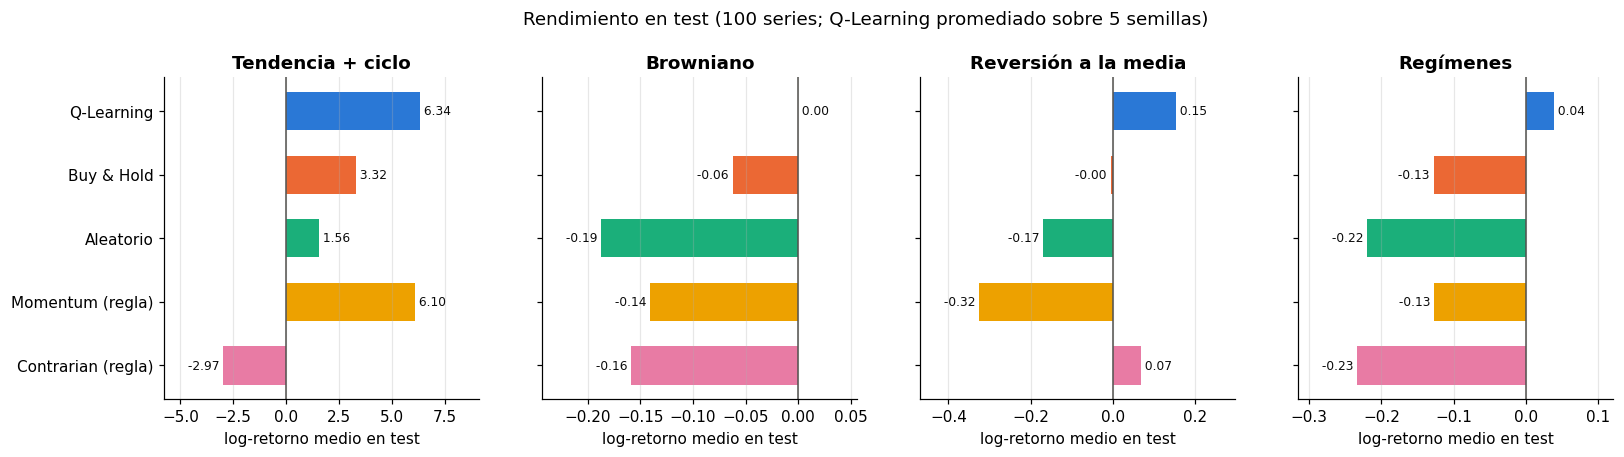

In [18]:
fig, axes = plt.subplots(1, 4, figsize=(17, 3.8))
show = ["Q-Learning", "Buy & Hold", "Aleatorio", "Momentum (regla)", "Contrarian (regla)"]
for ax, g in zip(axes, GENERATORS):
    vals = [table.loc[(g, a), "Log-ret. medio"] for a in show]
    ax.barh(range(len(show)), vals, color=[COLORS[a] for a in show], height=0.6)
    ax.axvline(0, color="#52514e", lw=1)
    ax.set_yticks(range(len(show)), show if g == list(GENERATORS)[0] else [""] * len(show))
    ax.invert_yaxis()
    ax.set_title(g)
    ax.set_xlabel("log-retorno medio en test")
    for k, v in enumerate(vals):
        ax.text(v, k, f" {v:.2f} ", va="center", ha="left" if v >= 0 else "right", fontsize=8, color="#0b0b0b")
    lo, hi = min(0, min(vals)), max(0, max(vals))
    pad = 0.3 * (hi - lo)
    ax.set_xlim(lo - pad, hi + pad)   # margen para que las etiquetas no pisen el eje
    ax.grid(axis="y", visible=False)
fig.suptitle("Rendimiento en test (100 series; Q-Learning promediado sobre 5 semillas)", y=1.04)
plt.savefig(f"{FIG_DIR}/comparativa_test.png", bbox_inches="tight")
plt.show()

**Análisis de los resultados en test**

- **Tendencia + ciclo (señal de *momentum*).**
  - Q-Learning obtiene un log-retorno medio de 6.34, frente a 3.32 de *buy & hold*, y supera a B&H en el 96 % de las series.
  - También mejora ligeramente la regla fija de momentum (6.10) y opera un 38 % menos (58 operaciones frente a 93), porque aprende histéresis (sección 9).
  - Es el problema más fácil: converge en unos 300 episodios.
- **Browniano (sin señal).**
  - El agente aprende a **no invertir nunca**. B&H pierde de media un 6 % geométrico, y las reglas y el agente aleatorio pierden más por las comisiones.
  - Es la estrategia esperada si se mira el crecimiento del capital: con μ = 0.0001 y σ = 0.02, el log-retorno esperado por paso (μ − σ²/2 = −0.0001) es negativo.
  - Matiz: en esperanza *aritmética*, B&H sí gana un poco (+0.01 % por paso). Esa ventaja es demasiado pequeña frente al ruido para que una tabla Q la detecte en 3000 episodios.
- **Reversión a la media (señal *contrarian* débil).**
  - Q-Learning es el claro ganador: +16.7 % geométrico, frente a −0.5 % de B&H y +7.1 % de la regla contrarian.
  - Supera a B&H en el 80 % de las series, con mejor Sharpe (0.55 frente a 0.15) y menor *drawdown* (17 % frente a 26 %).
  - Mejora a la regla fija porque aprende un contrarian **con histéresis**: compra tras caídas fuertes y mantiene hasta que la tendencia se vuelve positiva. Opera menos de la mitad de veces que la regla.
  - Es el problema que más tarda en converger: unos 2200 episodios.
- **Regímenes.**
  - Q-Learning gana un +4.0 %, frente al −12 % de B&H, y supera a B&H en el 69 % de las series. Es una ganancia pequeña pero consistente entre semillas (desviación típica 0.02).
  - No sigue la tendencia: se queda dentro con tendencias moderadas y **sale ante movimientos extremos en cualquier dirección**. Una |tendencia| grande suele delatar la alta volatilidad del régimen bajista (σ = 2.5 % frente a 1 %), lo que sugiere que el agente usa la tendencia como un *proxy* (ruidoso) de la volatilidad. La sección 10.1 lo confirma indirectamente: al darle la volatilidad como variable, el rendimiento se multiplica por cuatro.
- **Agente aleatorio.**
  - Hace unas 164 operaciones por episodio, cada una con un 0.1 % de comisión. Eso explica casi exactamente sus pérdidas (≈ −0.16 a −0.22 de log-retorno) en los tres mercados sin deriva fuerte.
  - Solo gana en *tendencia + ciclo*, gracias a la deriva del propio mercado.
- **Coste computacional.**
  - Cada agente (3000 episodios, ~1.5 M pasos) tarda ~3 min con 12 procesos en paralelo. Ese tiempo está inflado por la contención de CPU y por las evaluaciones periódicas en validación.
  - El tiempo hasta convergencia va de ~20 s (ciclo) a ~2 min (reversión). La dificultad de cada mercado se ve directamente en él: cuanto más débil la señal, más episodios hacen falta.

## 9. Análisis de las políticas aprendidas

Para interpretar la política se calcula, en cada intervalo de tendencia y según la posición actual, si el agente **queda invertido tras actuar**. Estando fuera, eso significa comprar; estando dentro, no vender. Se muestra la fracción de las 5 semillas que eligen quedar invertidas. Cada patrón tiene una forma reconocible:

- **momentum:** curva creciente;
- **contrarian:** curva decreciente;
- **buy & hold:** línea plana en 1;
- **siempre fuera:** línea plana en 0.

Si las curvas «fuera» y «dentro» no coinciden, el agente aplica **histéresis**: no deshace la posición por pequeñas variaciones, para ahorrar comisiones.

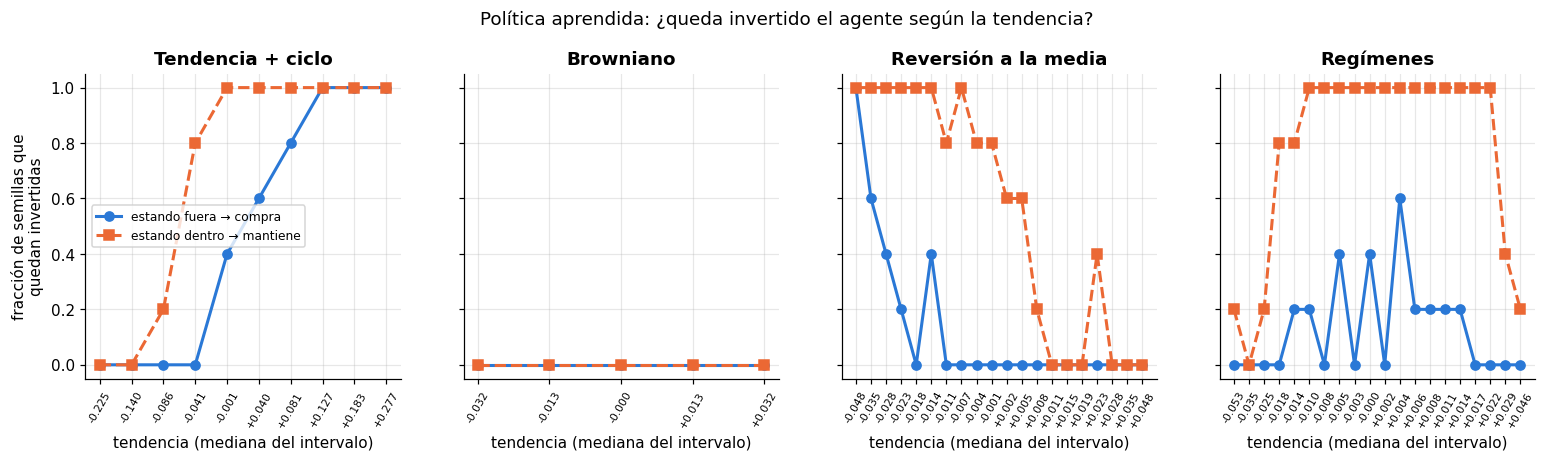

In [19]:
def invested_after(agent, disc, n_bins):
    """Matriz [posición, intervalo] -> 1 si la acción greedy deja al agente invertido."""
    out = np.zeros((2, n_bins))
    for b in range(n_bins):
        for pos in (0, 1):
            a = agent.greedy(b * 2 + pos)
            out[pos, b] = (a == 2) if pos == 0 else (a != 0)
    return out


fig, axes = plt.subplots(1, 4, figsize=(17, 3.6), sharey=True)
for ax, g in zip(axes, GENERATORS):
    nb = BEST_HP[g]["n_bins"]
    mats = np.array([invested_after(agent, disc, nb) for _, _, agent, disc, _ in RUNS[g]])
    disc0 = RUNS[g][0][3]
    edges = np.concatenate([[eda_trends[g].min()], disc0.edges[0], [eda_trends[g].max()]])
    centers = [np.median(eda_trends[g][(eda_trends[g] >= lo) & (eda_trends[g] <= hi)]) for lo, hi in zip(edges[:-1], edges[1:])]
    x = np.arange(nb)
    ax.plot(x, mats[:, 0].mean(0), "o-", color=COLORS["Q-Learning"], lw=2, ms=6, label="estando fuera → compra")
    ax.plot(x, mats[:, 1].mean(0), "s--", color=COLORS["Buy & Hold"], lw=2, ms=6, label="estando dentro → mantiene")
    ax.set_xticks(x, [f"{c:+.3f}" for c in centers], rotation=60, fontsize=7)
    ax.set_xlabel("tendencia (mediana del intervalo)")
    ax.set_title(g)
    ax.set_ylim(-0.05, 1.05)
axes[0].set_ylabel("fracción de semillas que\nquedan invertidas")
axes[0].legend(fontsize=8, loc="center left")
fig.suptitle("Política aprendida: ¿queda invertido el agente según la tendencia?", y=1.04)
plt.savefig(f"{FIG_DIR}/politicas.png", bbox_inches="tight")
plt.show()

Ejemplo de un episodio de test por generador, con la semilla 0. Los puntos verdes indican que el agente está invertido y los rojos que está fuera. El panel inferior compara el capital con *buy & hold*; en *tendencia + ciclo* se usa escala logarítmica.

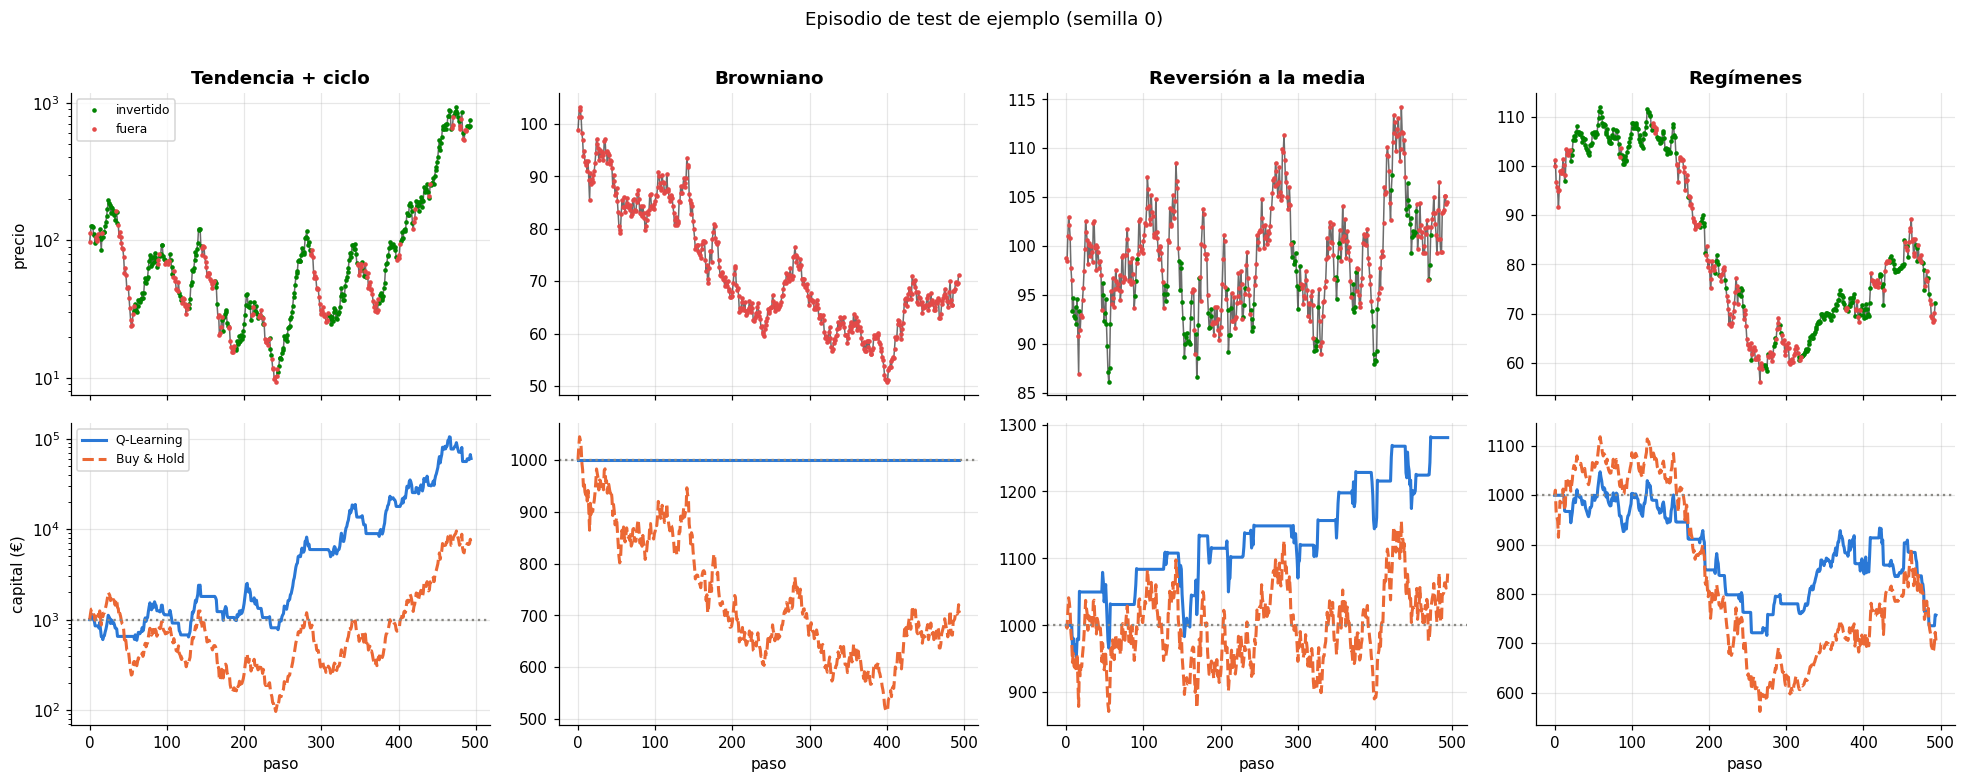

In [20]:
fig, axes = plt.subplots(2, 4, figsize=(18, 7), sharex="col")
for j, g in enumerate(GENERATORS):
    _, _, agent, disc, _ = RUNS[g][0]
    prices = test_sets[g][0]
    bal, pos, _ = run_episode(prices, agent.greedy_policy(disc))
    bal_bh, _, _ = run_episode(prices, lambda o: 2)
    valid = prices[5:-1]
    on, off = valid.copy(), valid.copy()
    on[pos == 0], off[pos == 1] = np.nan, np.nan
    ax = axes[0, j]
    ax.plot(valid, color="#0b0b0b", alpha=0.6, lw=1)
    ax.plot(on, ".", color="#008300", ms=4, label="invertido")
    ax.plot(off, ".", color="#e34948", ms=4, label="fuera")
    ax.set_title(g)
    if g == "Tendencia + ciclo":
        ax.set_yscale("log")
    ax = axes[1, j]
    ax.plot(bal, color=COLORS["Q-Learning"], lw=2, label="Q-Learning")
    ax.plot(bal_bh, color=COLORS["Buy & Hold"], ls="--", lw=2, label="Buy & Hold")
    ax.axhline(1000, color=COLORS["Siempre fuera"], ls=":", lw=1.5)
    if g == "Tendencia + ciclo":
        ax.set_yscale("log")
    ax.set_xlabel("paso")
axes[0, 0].set_ylabel("precio"); axes[1, 0].set_ylabel("capital (€)")
axes[0, 0].legend(fontsize=8); axes[1, 0].legend(fontsize=8)
fig.suptitle("Episodio de test de ejemplo (semilla 0)", y=1.01)
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/episodios_ejemplo.png", bbox_inches="tight")
plt.show()

**Interpretación de las políticas**

- **Tendencia + ciclo:** la forma de escalón creciente corresponde a *momentum*. La curva «estando dentro» está desplazada a la izquierda de la de «estando fuera»: el agente solo compra con tendencia ≥ 0, pero una vez dentro mantiene la posición hasta que la tendencia es claramente negativa (entre −0.04 y −0.09). Esta **histéresis** evita pagar comisiones en cada cambio de signo y explica que opere menos que la regla de momentum con un resultado mejor.
- **Browniano:** la línea plana en 0 corresponde a «siempre fuera».
- **Reversión a la media:** las dos curvas son decrecientes, es decir, *contrarian*. Solo compra en los intervalos más negativos (tendencia ≲ −0.03) y, una vez dentro, mantiene hasta que la tendencia pasa a ser positiva. Es la política esperada para un proceso con reversión: comprar cuando el precio cae y vender cuando se ha recuperado.
- **Regímenes:** la curva tiene forma de meseta. Estando dentro, el agente mantiene en todo el rango central de tendencias y vende en ambos extremos; estando fuera, apenas compra. Es la política que más varía entre semillas, como corresponde a una señal débil.

En los episodios de ejemplo se ve lo mismo: en *tendencia + ciclo* el agente está dentro en las fases alcistas del ciclo y fuera en las bajistas; en *reversión* compra en los valles; en *browniano* no opera.

## 10. Más allá de los mínimos

### 10.1 Estado ampliado

El análisis exploratorio mostró que la tendencia de 6 pasos apenas informa en *regímenes* y *reversión a la media*. Sin embargo, ambos procesos tienen una estructura que **sí** sería explotable con otras variables:

- **Regímenes:** el régimen bajista tiene una volatilidad 2.5 veces mayor (2.5 % frente a 1 %). La **volatilidad reciente**, la desviación típica de los 10 últimos log-retornos, debería identificar el régimen bastante mejor que la tendencia.
- **Reversión a la media:** la fuerza de reversión depende de la distancia del precio a su nivel de equilibrio. La **desviación respecto a la media móvil de 20 pasos** la aproxima sin conocer el nivel de equilibrio.

Se define `ExtendedTradingEnv`, que hereda **la misma dinámica y la misma recompensa** y solo amplía la observación a `[tendencia, posición, volatilidad, desviación MA20]`. El estado discreto tiene 5 × 4 × 5 × 2 = 200 estados. Los hiperparámetros $\alpha \in \{0.01, 0.05\}$ y $\gamma \in \{0.9, 0.99\}$ se reajustan con una rejilla pequeña (1500 episodios, 2 semillas). La rejilla se centra en la zona que fue buena para el modelo base, porque al haber más estados cada uno recibe menos visitas.

In [21]:
class ExtendedTradingEnv(SimpleTradingEnv):
    """Misma dinámica/recompensa; la observación añade volatilidad reciente y desviación respecto a MA20."""

    def __init__(self, prices):
        super().__init__(prices)
        self.observation_space = spaces.Box(low=np.array([-1, 0, 0, -1], dtype=np.float32),
                                            high=np.array([1, 1, np.inf, 1], dtype=np.float32), dtype=np.float32)

    def _get_obs(self):
        base = super()._get_obs()
        k = self.current_step
        log_rets = np.diff(np.log(self.prices[max(0, k - 10):k + 1]))
        hist = self.prices[max(0, k - 19):k + 1]
        dev = np.clip((hist[-1] - hist.mean()) / hist.mean(), -1, 1)
        return np.array([base[0], base[1], log_rets.std(), dev], dtype=np.float32)


EXT_BINS = {0: 5, 2: 4, 3: 5}


def ext_grid_job(gen_name, seed, hp):
    disc = Discretizer(gen_name, EXT_BINS, env_cls=ExtendedTradingEnv)
    agent, hist = train_q_learning(gen_name, disc, n_episodes=1500, env_cls=ExtendedTradingEnv, seed=seed, **hp)
    res = evaluate(val_sets[gen_name], lambda i: agent.greedy_policy(disc), ExtendedTradingEnv)
    return {"gen": gen_name, "seed": seed, **hp, "val_logret": res["log_ret"].mean()}


ext_path = f"{CACHE_DIR}/grid_estado_ampliado.csv"
if RECOMPUTE or not os.path.exists(ext_path):
    jobs = [(g, sd, {"alpha": a, "gamma": gm, "eps_min": 0.05, "decay_frac": 0.6})
            for g in GENERATORS for a in [0.01, 0.05] for gm in [0.9, 0.99] for sd in range(2)]
    pd.DataFrame(Parallel(n_jobs=N_JOBS)(delayed(ext_grid_job)(*j) for j in jobs)).to_csv(ext_path, index=False)
ext_grid = pd.read_csv(ext_path)
ext_best = ext_grid.groupby(["gen", "alpha", "gamma"], as_index=False).val_logret.mean()
ext_best = ext_best.loc[ext_best.groupby("gen").val_logret.idxmax()].set_index("gen").loc[list(GENERATORS)]
EXT_HP = {g: {"n_bins": None, "alpha": float(ext_best.loc[g, "alpha"]), "gamma": float(ext_best.loc[g, "gamma"]),
              "eps_min": 0.05, "decay_frac": 0.6} for g in GENERATORS}
ext_best

,alpha,gamma,val_logret
gen,,,
Tendencia + ciclo,0.01,0.9,6.463247
Browniano,0.01,0.9,0.000099
Reversión a la media,0.01,0.9,0.385410
Regímenes,0.01,0.9,0.162551


### 10.2 Double Q-Learning

Q-Learning estima el valor del estado siguiente con $\max_{a'} Q(s',a')$. Cuando las recompensas son muy ruidosas, como aquí (volatilidades del 1–10 % por paso frente a señales del orden de 0.01 %), ese máximo **sobreestima** sistemáticamente el valor de las acciones. El efecto puede llevar al agente a operar en exceso. *Double* Q-Learning (van Hasselt, 2010) desacopla la selección de la acción y su evaluación usando dos tablas. Se entrena con los mismos hiperparámetros que el Q-Learning base, para aislar el efecto del estimador.

Ambas variantes se entrenan con 5 semillas y 3000 episodios, igual que el modelo base.

In [22]:
ext_runs = cached(f"{CACHE_DIR}/agentes_estado_ampliado.joblib", lambda: Parallel(n_jobs=N_JOBS)(
    delayed(final_job)(g, sd, EXT_HP[g], False, ExtendedTradingEnv, EXT_BINS) for g in GENERATORS for sd in range(N_SEEDS)))
dq_runs = cached(f"{CACHE_DIR}/agentes_double_q.joblib", lambda: Parallel(n_jobs=N_JOBS)(
    delayed(final_job)(g, sd, BEST_HP[g], True) for g in GENERATORS for sd in range(N_SEEDS)))

for label, runs_all, env_cls in [("Q-Learning (estado ampliado)", ext_runs, ExtendedTradingEnv),
                                 ("Double Q-Learning", dq_runs, SimpleTradingEnv)]:
    for g in GENERATORS:
        runs = [r for r in runs_all if r[0] == g]
        per_seed = [evaluate(test_sets[g], lambda i, a=agent, d=disc: a.greedy_policy(d), env_cls) for _, _, agent, disc, _ in runs]
        res = pd.concat(per_seed, ignore_index=True)
        test_results[(g, label)] = res
        convs = [convergence_episode(h["val_ep"], h["val_logret"]) for *_, h in runs]
        t_ep = np.mean([h["train_time"] / FINAL_EPISODES for *_, h in runs])
        row = summarize(res, label, g, {
            "Std log-ret. entre semillas": np.std([r["log_ret"].mean() for r in per_seed]),
            "Episodios hasta convergencia": np.median(convs),
            "Tiempo hasta convergencia (s)": np.median(convs) * t_ep,
            "Tiempo total entrenamiento (s)": np.mean([h["train_time"] for *_, h in runs])})
        bh = test_results[(g, "Buy & Hold")]["log_ret"].values
        row["% series > B&H"] = 100 * np.mean(res["log_ret"].values > np.tile(bh, N_SEEDS))
        rows.append(row)

table = pd.DataFrame(rows).set_index(["Generador", "Agente"])
ext_order = ["Q-Learning", "Q-Learning (estado ampliado)", "Double Q-Learning", "Buy & Hold", "Aleatorio"]
table.loc[[(g, a) for g in GENERATORS for a in ext_order], main_cols + ["Std log-ret. entre semillas", "Episodios hasta convergencia"]].astype(float).round(3)

agentes_estado_ampliado.joblib: calculado en 976 s


agentes_double_q.joblib: calculado en 433 s


Log-ret. medio  \
Generador            Agente                                         
Tendencia + ciclo    Q-Learning                             6.338   
                     Q-Learning (estado ampliado)           6.579   
                     Double Q-Learning                      6.414   
                     Buy & Hold                             3.316   
                     Aleatorio                              1.558   
Browniano            Q-Learning                             0.000   
                     Q-Learning (estado ampliado)          -0.006   
                     Double Q-Learning                      0.000   
                     Buy & Hold                            -0.062   
                     Aleatorio                             -0.187   
Reversión a la media Q-Learning                             0.155   
                     Q-Learning (estado ampliado)           0.317   
                     Double Q-Learning                      0.188   
                     Buy & Hold                            -0.005   
                     Aleatorio                             -0.169   
Regímenes            Q-Learning                             0.040   
                     Q-Learning (estado ampliado)           0.154   
                     Double Q-Learning                      0.018   
                     Buy & Hold                            -0.128   
                     Aleatorio                             -0.220   

                                                   Ret. geométrico (%)  \
Generador            Agente                                              
Tendencia + ciclo    Q-Learning                              56472.568   
                     Q-Learning (estado ampliado)            71881.804   
                     Double Q-Learning                       60914.772   
                     Buy & Hold                               2655.989   
                     Aleatorio                                 375.064   
Browniano            Q-Learning                                  0.000   
                     Q-Learning (estado ampliado)               -0.567   
                     Double Q-Learning                           0.000   
                     Buy & Hold                                 -6.039   
                     Aleatorio                                 -17.058   
Reversión a la media Q-Learning                                 16.748   
                     Q-Learning (estado ampliado)               37.263   
                     Double Q-Learning                          20.628   
                     Buy & Hold                                 -0.484   
                     Aleatorio                                 -15.581   
Regímenes            Q-Learning                                  4.044   
                     Q-Learning (estado ampliado)               16.707   
                     Double Q-Learning                           1.773   
                     Buy & Hold                                -11.981   
                     Aleatorio                                 -19.734   

                                                   Ret. mediano (%)  \
Generador            Agente                                           
Tendencia + ciclo    Q-Learning                           67938.265   
                     Q-Learning (estado ampliado)         84039.735   
                     Double Q-Learning                    68866.220   
                     Buy & Hold                            2960.313   
                     Aleatorio                              443.073   
Browniano            Q-Learning                               0.000   
                     Q-Learning (estado ampliado)             0.000   
                     Double Q-Learning                        0.000   
                     Buy & Hold                              -0.945   
                     Aleatorio                              -16.443   
Reversión a la media Q-Learning                    

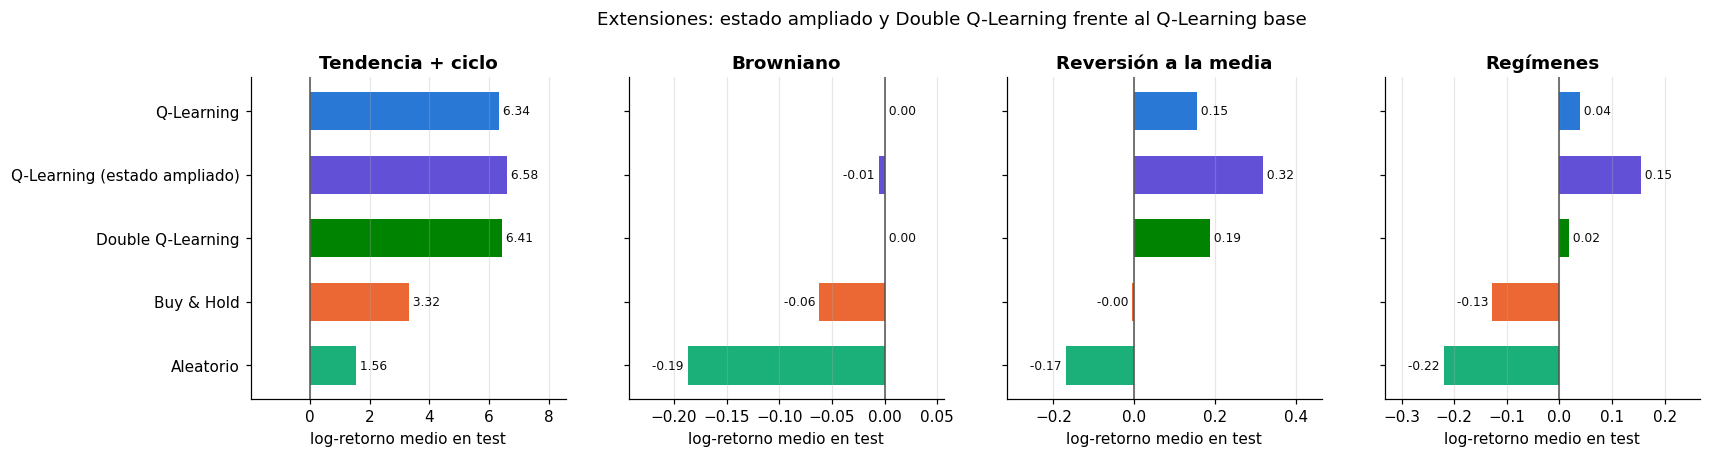

In [23]:
fig, axes = plt.subplots(1, 4, figsize=(17, 3.8))
for ax, g in zip(axes, GENERATORS):
    vals = [table.loc[(g, a), "Log-ret. medio"] for a in ext_order]
    ax.barh(range(len(ext_order)), vals, color=[COLORS[a] for a in ext_order], height=0.6)
    ax.axvline(0, color="#52514e", lw=1)
    ax.set_yticks(range(len(ext_order)), ext_order if g == list(GENERATORS)[0] else [""] * len(ext_order))
    ax.invert_yaxis()
    ax.set_title(g)
    ax.set_xlabel("log-retorno medio en test")
    for k, v in enumerate(vals):
        ax.text(v, k, f" {v:.2f} ", va="center", ha="left" if v >= 0 else "right", fontsize=8, color="#0b0b0b")
    lo, hi = min(0, min(vals)), max(0, max(vals))
    pad = 0.3 * (hi - lo)
    ax.set_xlim(lo - pad, hi + pad)   # margen para que las etiquetas no pisen el eje
    ax.grid(axis="y", visible=False)
fig.suptitle("Extensiones: estado ampliado y Double Q-Learning frente al Q-Learning base", y=1.04)
plt.savefig(f"{FIG_DIR}/comparativa_extensiones.png", bbox_inches="tight")
plt.show()

**Resultados de las extensiones** (mismos 100 series de test; 5 semillas por variante; las tres variantes comparten protocolo)

**Estado ampliado: mejora clara donde la tendencia no era suficiente.**

| Mercado | Q-Learning base | Estado ampliado | Variación |
|---|---|---|---|
| Regímenes | +0.040 (+4.0 %) | **+0.154 (+16.7 %)** | ×4 |
| Reversión a la media | +0.155 (+16.7 %) | **+0.317 (+37.3 %)** | ×2 |
| Tendencia + ciclo | 6.34 | 6.58 | +4 % (diferencia de 2 desv. típicas entre semillas) |
| Browniano | 0.000 | −0.006 | ligeramente peor |

- **Regímenes y reversión** son los mercados donde la tendencia de 6 pasos era una señal pobre y donde las nuevas variables encajan con la estructura del proceso (volatilidad para identificar el régimen, distancia a la media móvil para la reversión). El agente supera a *buy & hold* en el 75 % y el 94 % de las series respectivamente, con un Sharpe de 0.66 y 0.87 (frente a 0.22 y 0.55 del modelo base) y menor *drawdown*.
- **Tendencia + ciclo** apenas cambia: el *momentum* de 6 pasos ya capturaba la señal. Las variables añadidas son redundantes.
- **Browniano** es la comprobación de cordura. Sin señal que explotar, el estado ampliado (200 estados) introduce sobreajuste al ruido: el agente opera algo (8 operaciones por episodio, 1.9 % del tiempo invertido) y pierde un 0.6 %, en lugar de quedarse fuera. La pérdida es pequeña, pero es el coste de tener más estados con la misma cantidad de datos.
- **Coste.** El estado ampliado converge en un número de episodios comparable (1200 en reversión, 2200 en regímenes, frente a 2200 y 2000 del modelo base) pero entrena unas 2 veces más lento por episodio, por el cálculo extra de las variables en el entorno.

**Double Q-Learning: sin diferencias apreciables.**

- Las diferencias con el Q-Learning base están dentro del ruido entre semillas: ciclo 6.41 frente a 6.34 (desv. típica 0.1), reversión 0.188 frente a 0.155 (desv. típica 0.02–0.04) y regímenes 0.018 frente a 0.040 (desv. típica 0.03). Con 5 semillas no se puede afirmar que ninguna de las dos variantes sea mejor.
- La explicación probable es que el sesgo de sobreestimación del operador máx. es pequeño aquí: solo hay 3 acciones y, con α = 0.01, cada valor Q promedia muchas muestras. Se esperaría más efecto con muchas acciones o con α alto.
- Los dos algoritmos convergen en un número similar de episodios.


## 11. Exportación de resultados

La tabla completa se guarda en CSV para combinarla con los resultados de SARSA. Si SARSA se evalúa con las mismas semillas de test (`SEED_TEST + i`, `i = 0..99`, `N_STEPS = 500`), las filas de *baselines* son idénticas y basta con añadir las filas de SARSA.

In [24]:
table.astype(float).round(4).to_csv("resultados_qlearning.csv", encoding="utf-8-sig")
pd.DataFrame(BEST_HP).T.to_csv("hiperparametros_qlearning.csv", encoding="utf-8-sig")
print("Guardado: resultados_qlearning.csv, hiperparametros_qlearning.csv y figuras en", FIG_DIR)

Guardado: resultados_qlearning.csv, hiperparametros_qlearning.csv y figuras en figuras_qlearning


## 12. Conclusiones y limitaciones

**Resumen de resultados (test, 100 series nuevas por mercado).**

| Mercado | Qué había que aprender | Q-Learning base | Mejor extensión | Buy & Hold |
|---|---|---|---|---|
| Tendencia + ciclo | *Momentum* | **+56 000 %** (log-ret. 6.34) | estado ampliado: 6.58 | +2 656 % (3.32) |
| Browniano | Nada: no invertir | **0 %** (no opera) | — | −6.0 % |
| Reversión a la media | *Contrarian* con histéresis | **+16.7 %** | estado ampliado: **+37.3 %** | −0.5 % |
| Regímenes | Salir ante alta volatilidad | **+4.0 %** | estado ampliado: **+16.7 %** | −12.0 % |

1. **Q-Learning tabular supera a *buy & hold*, al agente aleatorio y a las reglas fijas en los cuatro mercados**, o los iguala cuando no hay nada que ganar (browniano). Las estrategias aprendidas son las esperadas para cada proceso: *momentum*, no invertir, *contrarian* y aversión a la volatilidad.
2. **Los resultados dependen de que exista una señal en el estado.** El análisis exploratorio (sección 2) ya predecía qué mercados serían aprendibles. Donde la señal es débil o inexistente, el agente aprende a no operar y se protege de las comisiones, que es la decisión racional.
3. **El hiperparámetro decisivo es α.** Con α ≥ 0.05 el ruido de las recompensas domina y el agente deja de operar. γ debe ser alto (0.99) cuando la señal tarda varios pasos en compensar la comisión. El nº de intervalos y ε tienen un efecto menor.
4. **Convergencia.** El tiempo de convergencia crece cuanto más débil es la señal: ~300 episodios en *tendencia + ciclo* (≈ 20 s), 2000–2200 en *reversión* y *regímenes* (≈ 100–125 s). Estos tiempos se midieron con 12 procesos en paralelo y evaluaciones periódicas incluidas, así que sirven para comparar mercados entre sí, no como medida absoluta.
5. **Enriquecer el estado compensa más que cambiar el algoritmo.** El estado ampliado multiplica por 2–4 el rendimiento en reversión y regímenes. *Double* Q-Learning no aporta una mejora distinguible del ruido.

**Limitaciones.**

- Los mercados son **sintéticos** y sus parámetros son conocidos. Los resultados no garantizan nada sobre series reales, donde las señales son más débiles y cambian con el tiempo.
- El entorno es de **todo o nada**, sin tamaño de posición, y la comisión es fija (0.1 %). No se ha estudiado la sensibilidad a la comisión.
- Los intervalos de la discretización se calibran con datos del mismo generador, algo que en un mercado real no sería posible sin sesgo de anticipación.
- El estado ampliado se ha diseñado a partir de la estructura **conocida** de cada generador. Es una prueba de que más información ayuda, no una solución que se pueda aplicar a ciegas.
- Con 5 semillas, las diferencias pequeñas (como las de *Double* Q-Learning) no son concluyentes.
- Los hiperparámetros se ajustan con una búsqueda en rejilla de 1000 episodios, mientras que el entrenamiento final usa 3000. Pueden existir configuraciones algo mejores fuera de la rejilla.

**Para combinar con SARSA.** `resultados_qlearning.csv` usa las semillas de test `SEED_TEST + i` (`i = 0..99`, 500 pasos). Si la libreta de SARSA usa las mismas, las filas de los *baselines* coinciden y basta con añadir las filas de SARSA a la tabla.
